# Data Preparation 3: Combine SATCAT and ELSET data
### 1. Combine the content of the 'decayedLEODebris.csv' and 'OMMs.csv' based on the Norad ID

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)

# read data SATCAT data from csv
decayedLEODebris_df = pd.read_csv('../Data/decayedLEODebris.csv')
print("Number of objects from SATCAT: ", len(decayedLEODebris_df))
decayedLEODebris_df.head()

Number of objects from SATCAT:  25798


,INTLDES,NORAD_CAT_ID,OBJECT_TYPE,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,PERIOD,INCLINATION,APOGEE,PERIGEE,RCS_SIZE
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,LARGE
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN
2,1960-003A,30,ROCKET BODY,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,88.38,51.25,194.0,194.0,NaN
3,1960-003C,33,DEBRIS,THOR ABLESTAR DEB,US,1960-04-13,AFETR,1960-07-17,93.59,51.29,615.0,285.0,NaN
4,1960-005B,35,ROCKET BODY,SL-3 R/B,CIS,1960-05-15,TTMTR,1960-07-17,88.48,64.89,199.0,199.0,NaN


In [33]:
# read ELSET data from csv
OMMs_df = pd.read_csv('../Data/OMMs.csv')
print("Number of objects from ELSET: ", len(OMMs_df))
OMMs_df.head()

Number of objects from ELSET:  10420


,OBJECT_NAME,OBJECT_ID,EPOCH,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,NORAD_CAT_ID,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,APOAPSIS,PERIAPSIS,OBJECT_TYPE,RCS_SIZE,LAUNCH_DATE,SITE,DECAY_DATE
0,JUNO II R/B,1959-009B,1982-01-13 15:21:06.439968,14.783345,0.018309,50.3043,233.6360,296.4831,61.7000,23,16909,0.000982,0.000093,0.0,7012.727,97.406,762.990,506.194,ROCKET BODY,MEDIUM,1959-10-13,AFETR,1989-07-16
1,THOR ABLE R/B,1960-002A,1987-09-12 00:12:35.555904,14.851805,0.001762,48.3748,236.4746,95.6844,264.6079,28,46764,0.000080,0.000006,0.0,6991.160,96.957,625.344,600.706,ROCKET BODY,LARGE,1960-04-01,AFETR,1991-07-03
2,TBA - TO BE ASSIGNED,1960-003A,1961-04-17 11:27:12.924288,15.653967,0.012542,51.2500,272.4964,204.3932,155.8967,30,5670,0.000000,0.001202,0.0,6750.239,91.989,456.763,287.445,TBA,NaN,NaN,NaN,NaN
3,TBA - TO BE ASSIGNED,1960-003C,1960-08-06 21:56:44.331935,15.381096,0.024375,51.2879,72.6448,330.1842,30.5053,33,1770,0.000000,0.000019,0.0,6829.840,93.621,618.180,285.231,TBA,NaN,NaN,NaN,NaN
4,TBA - TO BE ASSIGNED,1960-005B,1960-06-08 00:20:02.506559,15.861291,0.001599,64.8899,183.4791,52.6307,307.4432,35,380,0.000000,0.001764,0.0,6691.288,90.787,323.852,302.454,TBA,NaN,NaN,NaN,NaN


In [34]:
# merge the two dataframes with outer join
combined_df = pd.merge(decayedLEODebris_df, OMMs_df, on='NORAD_CAT_ID', how='outer')
combined_df.head()

,INTLDES,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE_x,DECAY,PERIOD_x,INCLINATION_x,APOGEE,PERIGEE,RCS_SIZE_x,OBJECT_NAME,OBJECT_ID,EPOCH,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD_y,APOAPSIS,PERIAPSIS,OBJECT_TYPE_y,RCS_SIZE_y,LAUNCH_DATE,SITE_y,DECAY_DATE
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,LARGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1959-009B,23,ROCKET BODY,JUNO II R/B,US,1959-10-13,AFETR,1989-07-16,89.24,50.27,249.0,225.0,MEDIUM,JUNO II R/B,1959-009B,1982-01-13 15:21:06.439968,14.783345,0.018309,50.3043,233.6360,296.4831,61.7000,16909.0,0.000982,0.000093,0.0,7012.727,97.406,762.990,506.194,ROCKET BODY,MEDIUM,1959-10-13,AFETR,1989-07-16
3,1960-002A,28,ROCKET BODY,THOR ABLE R/B,US,1960-04-01,AFETR,1991-07-03,87.80,48.34,168.0,163.0,LARGE,THOR ABLE R/B,1960-002A,1987-09-12 00:12:35.555904,14.851805,0.001762,48.3748,236.4746,95.6844,264.6079,46764.0,0.000080,0.000006,0.0,6991.160,96.957,625.344,600.706,ROCKET BODY,LARGE,1960-04-01,AFETR,1991-07-03
4,1960-003A,30,ROCKET BODY,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,88.38,51.25,194.0,194.0,NaN,TBA - TO BE ASSIGNED,1960-003A,1961-04-17 11:27:12.924288,15.653967,0.012542,51.2500,272.4964,204.3932,155.8967,5670.0,0.000000,0.001202,0.0,6750.239,91.989,456.763,287.445,TBA,NaN,NaN,NaN,NaN


#### Columns with the same name have a _x suffix if they come from SATCAT and _y if they come from ELSET dataframe.

### 2. Examine the objects without OMM data to see if they can be dropped unproblematically

In [35]:
# count objects without OMM data
print(combined_df['EPOCH'].isnull().sum())

15378


In [36]:
# extract rows whithout OMM data
missing_OMMs_df = combined_df[combined_df['EPOCH'].isnull()].copy()
missing_OMMs_df.head()

,INTLDES,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE_x,DECAY,PERIOD_x,INCLINATION_x,APOGEE,PERIGEE,RCS_SIZE_x,OBJECT_NAME,OBJECT_ID,EPOCH,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD_y,APOAPSIS,PERIAPSIS,OBJECT_TYPE_y,RCS_SIZE_y,LAUNCH_DATE,SITE_y,DECAY_DATE
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,LARGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
103,1962-019B,296,ROCKET BODY,ATLAS D 7 R/B,US,1962-05-24,AFETR,1962-05-25,88.80,32.50,292.0,138.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
189,1961-015FN,476,DEBRIS,THOR ABLESTAR DEB,US,1961-06-29,AFETR,2014-04-02,88.97,67.01,240.0,208.0,SMALL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
190,1961-015FP,477,DEBRIS,THOR ABLESTAR DEB,US,1961-06-29,AFETR,1982-01-18,90.86,66.58,335.0,299.0,SMALL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
# check how often which object type occurs in the missing OMM data and overall data
combined_type_counts = combined_df['OBJECT_TYPE_x'].value_counts(normalize=True) * 100
missing_type_counts = missing_OMMs_df['OBJECT_TYPE_x'].value_counts(normalize=True) * 100
print("Combined type counts: ", combined_type_counts, "\n")
print("Missing type counts: ", missing_type_counts)

Combined type counts:  OBJECT_TYPE_x
DEBRIS         84.48717
ROCKET BODY    15.51283
Name: proportion, dtype: float64 

Missing type counts:  OBJECT_TYPE_x
DEBRIS         87.508128
ROCKET BODY    12.491872
Name: proportion, dtype: float64


In [38]:
# check size of objects
combined_size_counts = (combined_df['RCS_SIZE_x'].value_counts(normalize=True) * 100).reindex(['SMALL', 'MEDIUM', 'LARGE'])
missing_size_counts = (missing_OMMs_df['RCS_SIZE_x'].value_counts(normalize=True) * 100).reindex(['SMALL', 'MEDIUM', 'LARGE'])
print("Combined size counts: ", combined_size_counts, "\n")
print("Missing size counts: ", missing_size_counts)

Combined size counts:  RCS_SIZE_x
SMALL     64.196159
MEDIUM    19.621224
LARGE     16.182617
Name: proportion, dtype: float64 

Missing size counts:  RCS_SIZE_x
SMALL     72.055359
MEDIUM    13.508539
LARGE     14.436101
Name: proportion, dtype: float64


Missing_TLEs_df 'LAUNCH' column datatype: 

 datetime64[ns]
combined_df 'LAUNCH' column datatype:  datetime64[ns]


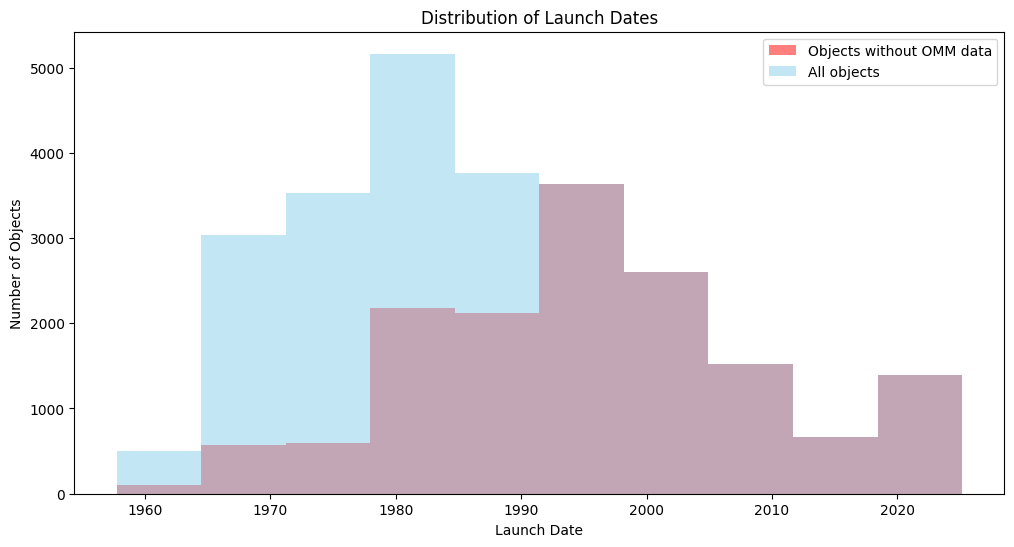

In [39]:
# display launch dates on a timeline
# convert the launch date to a datetime object
missing_OMMs_df['LAUNCH'] = pd.to_datetime(missing_OMMs_df['LAUNCH'])
combined_df['LAUNCH'] = pd.to_datetime(combined_df['LAUNCH'])

# show types of launch and decay date columns
print("Missing_TLEs_df 'LAUNCH' column datatype: ", missing_OMMs_df['LAUNCH'].dtype)
print("combined_df 'LAUNCH' column datatype: ", combined_df['LAUNCH'].dtype)

# plot the launch dates
plt.figure(figsize=(12, 6))
plt.hist(missing_OMMs_df['LAUNCH'], bins=10, color='red', alpha=0.5, label='Objects without OMM data')
plt.hist(combined_df['LAUNCH'], bins=10, color='skyblue', alpha=0.5, label='All objects')
plt.xlabel('Launch Date')
plt.ylabel('Number of Objects')
plt.title('Distribution of Launch Dates')
plt.legend()
plt.show()

Missing_OMMs_df 'DECAY' column datatype:  datetime64[ns]
combined_df 'DECAY' column datatype:  datetime64[ns]


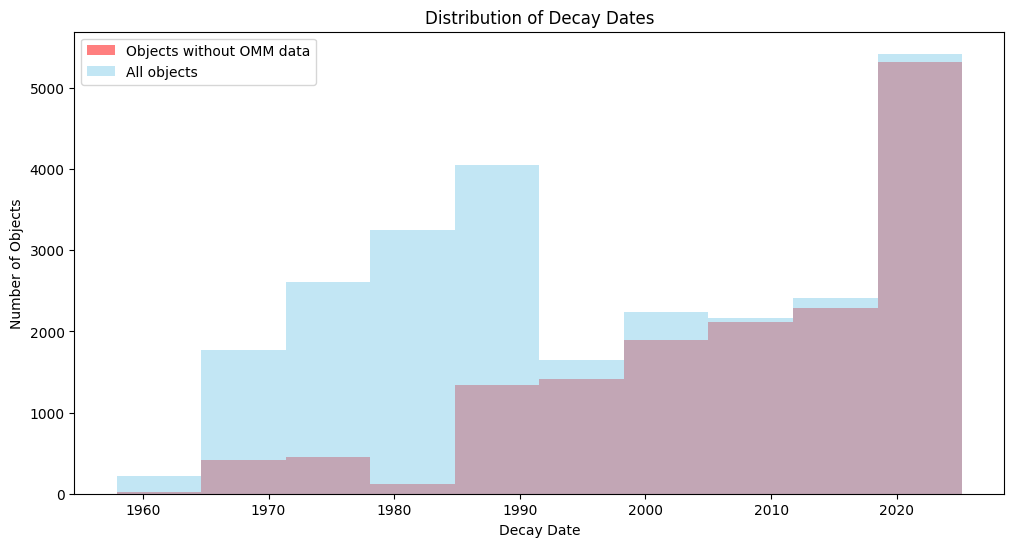

In [40]:
# display decay dates on a timeline
# convert the decay date to a datetime object
missing_OMMs_df['DECAY'] = pd.to_datetime(missing_OMMs_df['DECAY'])
combined_df['DECAY'] = pd.to_datetime(combined_df['DECAY'])

# check datatypes of decay date columns
print("Missing_OMMs_df 'DECAY' column datatype: ", missing_OMMs_df['DECAY'].dtype)
print("combined_df 'DECAY' column datatype: ", combined_df['DECAY'].dtype)

# plot the launch dates
plt.figure(figsize=(12, 6))
plt.hist(missing_OMMs_df['DECAY'], bins=10, color='red', alpha=0.5, label='Objects without OMM data')
plt.hist(combined_df['DECAY'], bins=10, color='skyblue', alpha=0.5, label='All objects')
plt.xlabel('Decay Date')
plt.ylabel('Number of Objects')
plt.title('Distribution of Decay Dates')
plt.legend()
plt.show()

In [41]:
# Calculate Lifetime of the Objects since the distribution of launch and decay dates is similar and suggests that maybe all objects had a too short lifetime to record OMMs
missing_OMMs_df.insert(8, 'LIFETIME', missing_OMMs_df['DECAY'] - missing_OMMs_df['LAUNCH'])
# Calculate Lifetime of all objects
combined_df.insert(8, 'LIFETIME', combined_df['DECAY'] - combined_df['LAUNCH'])

In [42]:
# review statistics of the lifetime columns
print("Lifetime statistics over all objects:")
print(combined_df['LIFETIME'].describe(), "\n")
print("Lifetime statistics over objects without OMM data:")
print(missing_OMMs_df['LIFETIME'].describe())

Lifetime statistics over all objects:
count                           25798
mean     3508 days 05:27:55.943871616
std      4762 days 12:41:51.528292352
min                   0 days 00:00:00
25%                  33 days 00:00:00
50%                 923 days 00:00:00
75%                5732 days 18:00:00
max               23115 days 00:00:00
Name: LIFETIME, dtype: object 

Lifetime statistics over objects without OMM data:
count                           15378
mean     4616 days 11:18:02.949668416
std      5208 days 02:03:59.979264128
min                   0 days 00:00:00
25%                 119 days 00:00:00
50%                2056 days 00:00:00
75%                8201 days 00:00:00
max               23105 days 00:00:00
Name: LIFETIME, dtype: object


#### Objects without OMM data can be dropped unproblematically since they mostly had a relatively short lifetime and thus the explaination seems plausible that there was no chance to record OMMs.

In [43]:
# show objects count
print("Number of all objects: ", len(combined_df))
# drop objects without OMM data
combined_df.dropna(subset=['OBJECT_ID'], inplace=True)
# show number of remaining objects
print("Remaining objects: ", len(combined_df))

Number of all objects:  25798
Remaining objects:  10420


### 3. Drop not needed columns: Check duplicate columns to see if they contain the same values.  If they do not, check why and which one makes more sense to drop. 

In [44]:
# compare columns with same content to check if they contain the same values
# List of column names to compare
columns_to_compare = [
    'OBJECT_TYPE', 'SITE', 'PERIOD', 'INCLINATION', 'RCS_SIZE'
]

# Initialize a dictionary to store the columns that are not equal
unequal_columns = {}

# Loop through the columns and check for inequality
for col in columns_to_compare:
    are_equal = combined_df[f'{col}_x'].equals(combined_df[f'{col}_y'])
    print(f"{col}: {are_equal}")
    if not are_equal:
        unequal_columns[f'{col}_x'] = combined_df[f'{col}_x']
        unequal_columns[f'{col}_y'] = combined_df[f'{col}_y']

# Create a DataFrame out of the unequal columns
unequal_df = pd.DataFrame(unequal_columns)

print("\nComparison of unequal columns side by side:")
unequal_df.head()

OBJECT_TYPE: False
SITE: False
PERIOD: False
INCLINATION: False
RCS_SIZE: False

Comparison of unequal columns side by side:


,OBJECT_TYPE_x,OBJECT_TYPE_y,SITE_x,SITE_y,PERIOD_x,PERIOD_y,INCLINATION_x,INCLINATION_y,RCS_SIZE_x,RCS_SIZE_y
2,ROCKET BODY,ROCKET BODY,AFETR,AFETR,89.24,97.406,50.27,50.3043,MEDIUM,MEDIUM
3,ROCKET BODY,ROCKET BODY,AFETR,AFETR,87.80,96.957,48.34,48.3748,LARGE,LARGE
4,ROCKET BODY,TBA,AFETR,NaN,88.38,91.989,51.25,51.2500,NaN,NaN
5,DEBRIS,TBA,AFETR,NaN,93.59,93.621,51.29,51.2879,NaN,NaN
6,ROCKET BODY,TBA,TTMTR,NaN,88.48,90.787,64.89,64.8899,NaN,NaN


In [45]:
# check null values
# object type
print("OBJECT_TYPE_x: ", unequal_df['OBJECT_TYPE_x'].isnull().sum())
print("OBJECT_TYPE_y: ", unequal_df['OBJECT_TYPE_y'].value_counts()['TBA'] + unequal_df['OBJECT_TYPE_y'].isnull().sum()) # count "TBA" and null values
# site
print("SITE_x: ", unequal_df['SITE_x'].isnull().sum())
print("SITE_y: ", unequal_df['SITE_y'].isnull().sum())
# period
print("PERIOD_x: ", unequal_df['PERIOD_x'].isnull().sum())
print("PERIOD_y: ", unequal_df['PERIOD_y'].isnull().sum())
# inclination
print("INCLINATION_x: ", unequal_df['INCLINATION_x'].isnull().sum())
print("INCLINATION_y: ", unequal_df['INCLINATION_y'].isnull().sum())
# RCS_SIZE
print("RCS_SIZE_x: ", unequal_df['RCS_SIZE_x'].isnull().sum())
print("RCS_SIZE_y: ", unequal_df['RCS_SIZE_y'].isnull().sum())


OBJECT_TYPE_x:  0
OBJECT_TYPE_y:  5281
SITE_x:  0
SITE_y:  6446
PERIOD_x:  0
PERIOD_y:  0
INCLINATION_x:  0
INCLINATION_y:  0
RCS_SIZE_x:  5101
RCS_SIZE_y:  6481


In [46]:
# delete columns 
combined_df.drop(columns=[
    'OBJECT_TYPE_y', # for y some object types were still to be assigned (TBA)
    'SITE_y', # keep x since it has no null values
    'PERIOD_x', # keep y since it is from the OMM 
    'INCLINATION_x', # keep y since it is from the OMM
    'RCS_SIZE_y' # keep x since it has less null values
    ], inplace=True)

# rename columns
combined_df.rename(columns={
    'OBJECT_TYPE_x': 'OBJECT_TYPE',
    'SITE_x': 'SITE',
    'PERIOD_y': 'PERIOD',
    'INCLINATION_y': 'INCLINATION',
    'RCS_SIZE_x': 'RCS_SIZE'
}, inplace=True)

In [47]:
# check datatypes of launch columns
print("LAUNCH: ", combined_df['LAUNCH'].dtype)
print("LAUNCH_DATE: ", combined_df['LAUNCH_DATE'].dtype)

LAUNCH:  datetime64[ns]
LAUNCH_DATE:  object


In [48]:
# convert launch column to datetime
combined_df['LAUNCH_DATE'] = pd.to_datetime(combined_df['LAUNCH'])

In [49]:
# compare launch columns 
print("Launch: ", combined_df['LAUNCH_DATE'].equals(combined_df['LAUNCH']))

Launch:  True


In [50]:
# drop launch and decay columns (Decay can be dropped since the lifetime is already calculated)
combined_df.drop(columns=['LAUNCH_DATE', 'DECAY_DATE', 'DECAY'], inplace=True)

In [51]:
# compare Object ID and International Designator
print(combined_df['OBJECT_ID'].equals(combined_df['INTLDES']))

False


In [52]:
# show rows where Object ID and International Designator are not equal with only the relevant columns
combined_df[combined_df['OBJECT_ID'] != combined_df['INTLDES']][['OBJECT_ID', 'INTLDES']]

,OBJECT_ID,INTLDES
2331,1966-025F,1966-063F
5873,1976-124C,1976-037AB
6007,1976-124D,1976-124C
6010,1976-124E,1976-124D
6016,1976-124F,1976-124E
6017,1976-124G,1976-124F
6018,1976-124H,1976-124G
6019,1976-124J,1976-124H
6020,1976-124K,1976-124J
6021,1976-124L,1976-124K


In [53]:
# the differences seem to come from the fact that ELSET data (OBJECT_ID) gets updated more frequently and reflects fragmentations and reassignments 
# the SATCAT data (INTLDES) retains historical launch assignments 
# therefore: keep OBJECT_ID and drop INTLDES
combined_df.drop(columns=['INTLDES'], inplace=True)
# rename to INTLDES since it describes the data better
combined_df.rename(columns={'OBJECT_ID': 'INTLDES'}, inplace=True)

In [54]:
# compare SATNAME and OBJECT_NAME
print(combined_df['SATNAME'].equals(combined_df['OBJECT_NAME']))

False


In [55]:
# show columns where they are not the same
combined_df[combined_df['SATNAME'] != combined_df['OBJECT_NAME']][['SATNAME', 'OBJECT_NAME']]

,SATNAME,OBJECT_NAME
4,THOR ABLESTAR R/B,TBA - TO BE ASSIGNED
5,THOR ABLESTAR DEB,TBA - TO BE ASSIGNED
6,SL-3 R/B,TBA - TO BE ASSIGNED
7,SPUTNIK 4 DEB,TBA - TO BE ASSIGNED
8,SPUTNIK 4 DEB,TBA - TO BE ASSIGNED
...,...,...
11488,SL-4 DEB,TBA - TO BE ASSIGNED
11489,COSMOS 1646 DEB,TBA - TO BE ASSIGNED
11490,COSMOS 1646 DEB,TBA - TO BE ASSIGNED
11492,SL-12 R/B(1),TBA - TO BE ASSIGNED


In [56]:
# drop OBJECT_NAME since some object names are still to be assigned (TBA)
combined_df.drop(columns=['OBJECT_NAME'], inplace=True)

In [57]:
# drop PERIGEE and APOGEE since PERIAPOSIS and APOAPSIS come from the OMM data
combined_df.drop(columns=['PERIGEE', 'APOGEE'], inplace=True)

In [58]:
# change order of columns
combined_df = combined_df[['NORAD_CAT_ID', 'INTLDES', 'SATNAME', 'OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', # information from SATCAT
                           'EPOCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD', # OMM information
                           'LIFETIME']] # label
combined_df.head()

,NORAD_CAT_ID,INTLDES,SATNAME,OBJECT_TYPE,COUNTRY,SITE,LAUNCH,EPOCH,PERIAPSIS,APOAPSIS,ARG_OF_PERICENTER,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,LIFETIME
2,23,1959-009B,JUNO II R/B,ROCKET BODY,US,AFETR,1959-10-13,1982-01-13 15:21:06.439968,506.194,762.990,296.4831,14.783345,0.018309,50.3043,233.6360,61.7000,16909.0,0.000982,0.000093,0.0,7012.727,97.406,10869 days
3,28,1960-002A,THOR ABLE R/B,ROCKET BODY,US,AFETR,1960-04-01,1987-09-12 00:12:35.555904,600.706,625.344,95.6844,14.851805,0.001762,48.3748,236.4746,264.6079,46764.0,0.000080,0.000006,0.0,6991.160,96.957,11415 days
4,30,1960-003A,THOR ABLESTAR R/B,ROCKET BODY,US,AFETR,1960-04-13,1961-04-17 11:27:12.924288,287.445,456.763,204.3932,15.653967,0.012542,51.2500,272.4964,155.8967,5670.0,0.000000,0.001202,0.0,6750.239,91.989,492 days
5,33,1960-003C,THOR ABLESTAR DEB,DEBRIS,US,AFETR,1960-04-13,1960-08-06 21:56:44.331935,285.231,618.180,330.1842,15.381096,0.024375,51.2879,72.6448,30.5053,1770.0,0.000000,0.000019,0.0,6829.840,93.621,95 days
6,35,1960-005B,SL-3 R/B,ROCKET BODY,CIS,TTMTR,1960-05-15,1960-06-08 00:20:02.506559,302.454,323.852,52.6307,15.861291,0.001599,64.8899,183.4791,307.4432,380.0,0.000000,0.001764,0.0,6691.288,90.787,63 days


In [59]:
# save to csv
combined_df.to_csv('../Data/Combined.csv', index=False)